# Figuras finais do INSECTS na Semana 10

Reproduzo os sete gráficos do relatório com a média das seeds 42, 43 e 44. A comparação usa 66 runs completos e exclui Online com Hoeffding nos dois fluxos. Para qualidade, calculo cada métrica por run na interseção dos eventos avaliados em todas as políticas e seeds de cada fluxo.

## Ambiente e fontes

Use Python 3.12. Na raiz, execute `uv sync --extra plots` e em seguida `uv pip install pandas jupyterlab ipykernel`. Abra o notebook com o kernel da mesma virtualenv.

- **Modo consolidado.** Leio os dados por seed arquivados em `docs/evidencias/semana-10/insects`. O modo padrão reproduz o relatório sem consultar a AWS.
- **Consulta de uma seed no MLflow.** Use `BENCHMARK_FIGURES_MODE=mlflow`, escolha `BENCHMARK_FIGURES_SEED` e forneça `MLFLOW_TRACKING_URI`. Para SageMaker, inclua `--extra aws-mlflow --extra datasets` no comando de instalação e configure a autenticação AWS do ambiente. Este modo é uma inspeção individual.

[Índice de evidências e dados](../docs/evidencias/semana-10/insects/README.md)


In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "notebooks" / "benchmark_figure_data.py").is_file()
)
sys.path.insert(0, str(ROOT / "notebooks"))

In [2]:
from benchmark_figure_data import from_campaign, from_mlflow
from benchmark_figures import (
    detector_timeline,
    export_figures,
    logistic_trajectories,
    paired_f1,
    quality_cost,
    quality_retention,
    recovery_bars,
    regime_map,
)

MODO = os.getenv("BENCHMARK_FIGURES_MODE", "consolidado")
SEED = int(os.getenv("BENCHMARK_FIGURES_SEED", "42"))
CAPTURA = Path(os.getenv("BENCHMARK_INSECTS_DIR", ROOT / "docs/evidencias/semana-10/insects")).expanduser()
SAIDA = Path(os.getenv("BENCHMARK_FIGURES_DIR", ROOT / "reports/figuras-insects")).expanduser()

# No modo MLflow, o inventário aceita qualquer CSV com colunas run e seed.
INVENTARIOS = [CAPTURA / "dados/runs.csv"]
RUN_IDS_ADICIONAIS = []
RUN_IDS_EXCLUIDOS = []
TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", "")


## Carregar a evidência

Confiro a cobertura de cada combinação e a cardinalidade do recorte pareado. Calculo a média aritmética entre as seeds para cada resultado. Na consulta individual ao MLflow, confiro a versão do fluxo e o F1 das predições, verificando a identidade e os rótulos antes do pareamento.

In [3]:
if MODO == "consolidado":
    evidence = from_campaign(CAPTURA)
elif MODO == "mlflow":
    from mlflow import MlflowClient, set_tracking_uri

    if not TRACKING_URI:
        raise ValueError("Defina MLFLOW_TRACKING_URI para consultar o servidor.")
    # The SageMaker auth provider reads the process-wide tracking URI.
    set_tracking_uri(TRACKING_URI)
    inventory_seeds = {}
    for path in INVENTARIOS:
        inventory = pd.read_csv(path, usecols=["run", "seed"], dtype={"run": str}, keep_default_na=False)
        for row in inventory.itertuples(index=False):
            if row.run:
                known_seed = inventory_seeds.setdefault(row.run, int(row.seed))
                if known_seed != int(row.seed):
                    raise ValueError(f"Conflito de seed nos inventários do run {row.run}.")
    candidates = [run for run, seed in inventory_seeds.items() if seed == SEED] + RUN_IDS_ADICIONAIS
    selected_ids = [run for run in candidates if run not in RUN_IDS_EXCLUIDOS]
    if not selected_ids:
        raise ValueError(f"Nenhum run selecionado para a seed {SEED}.")
    evidence = from_mlflow(
        MlflowClient(tracking_uri=TRACKING_URI), selected_ids, SEED, inventory_seeds=inventory_seeds
    )
else:
    raise ValueError("Escolha um modo de entrada entre consolidado e mlflow.")

display(
    evidence.paired.groupby("dataset").agg(
        configuracoes=("run", "nunique"), exemplos_comuns=("avaliados", "first")
    )
)


,configuracoes,exemplos_comuns
dataset,,
Abrupto,11,236587.0
Recorrente,11,301228.0


## Construir as sete figuras

Uso o recorte pareado para F1 e o run integral para custo, atualizações e retenção. Nas séries temporais, faço a média das janelas registradas na mesma posição pelas três seeds. Na recuperação, faço a média das seeds que atingiram o alvo. As barras e faixas de dispersão do F1 mostram um desvio padrão amostral.

In [4]:
with plt.ioff():
    figures = {
        "01-f1-por-regime": regime_map(evidence),
        "02-fitas-temporais-adwin": detector_timeline(evidence),
        "03-recuperacao-por-drift": recovery_bars(evidence),
        "04-f1-custo-atualizacoes": quality_cost(evidence),
        "05-f1-pareado": paired_f1(evidence),
        "06-trajetorias-logistica": logistic_trajectories(evidence),
        "07-qualidade-retencao": quality_retention(evidence),
    }


## Exportar e inspecionar

O PDF reúne os sete gráficos. Os PNGs ficam na subpasta `figuras`. Para atualizar o pacote do relatório, aponte `BENCHMARK_FIGURES_DIR` para a pasta do próprio pacote.

7 figuras exportadas para docs/evidencias/semana-10/insects
PDF: figuras-finais-insects.pdf


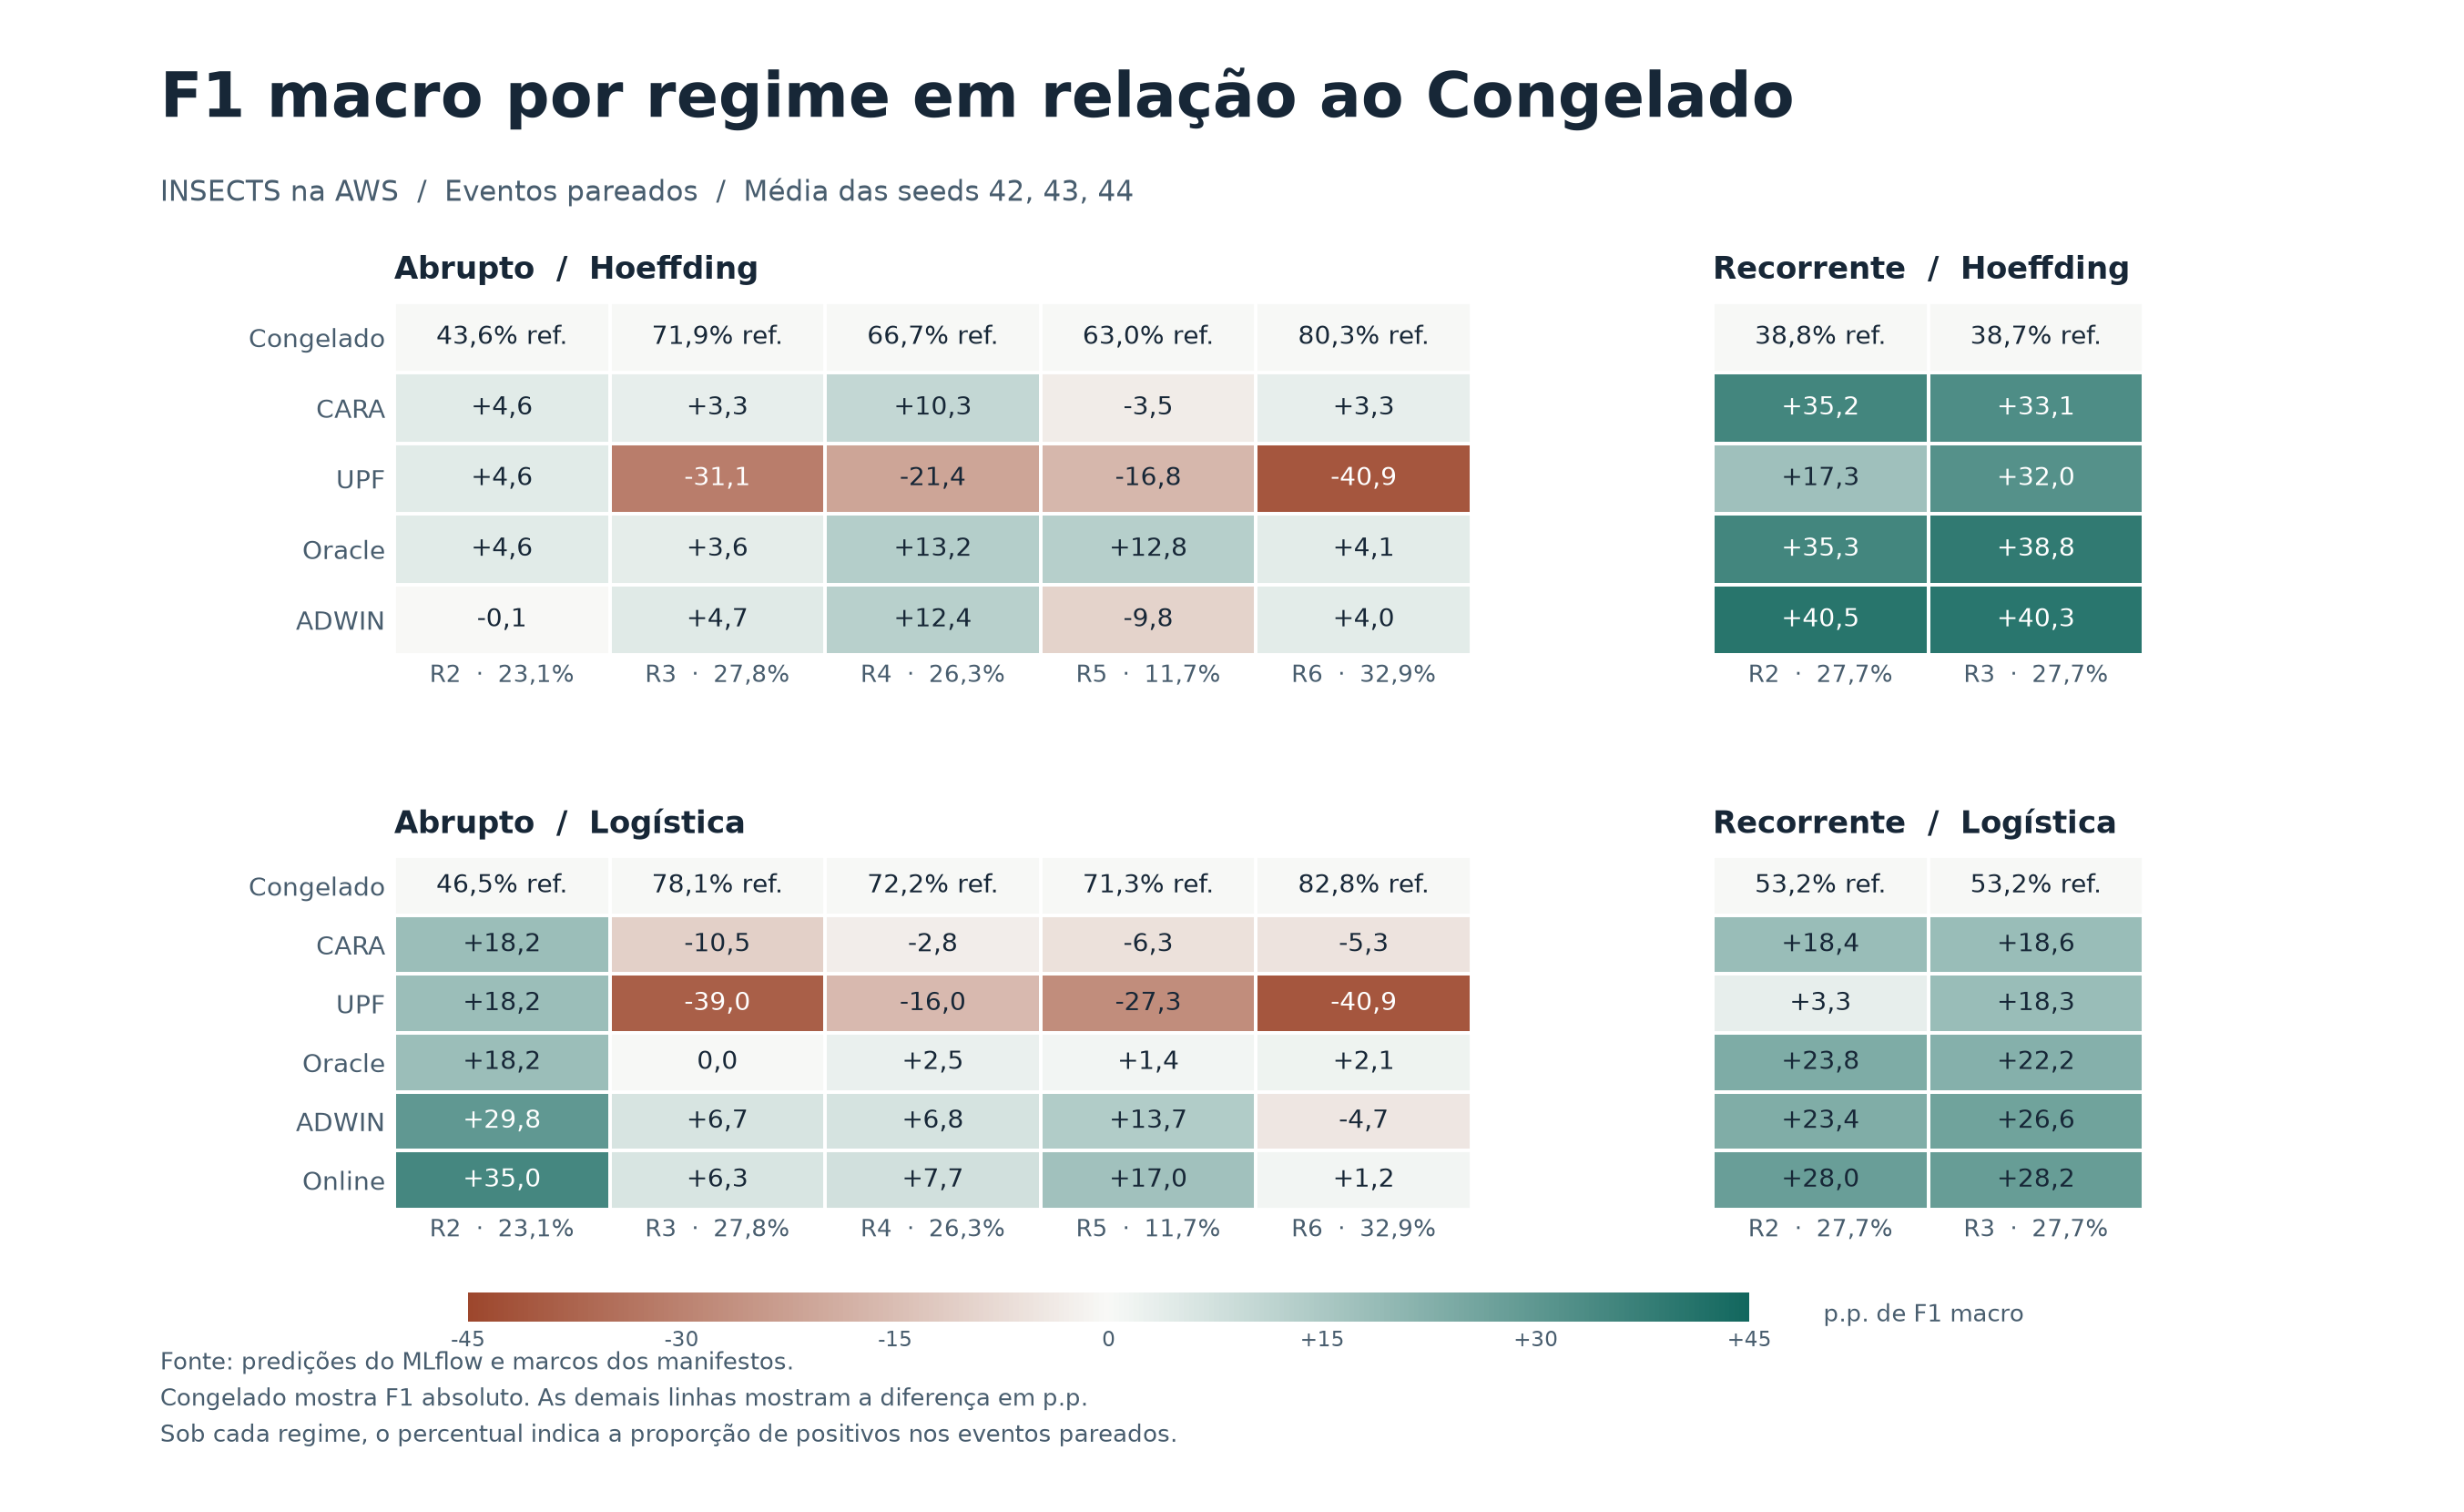

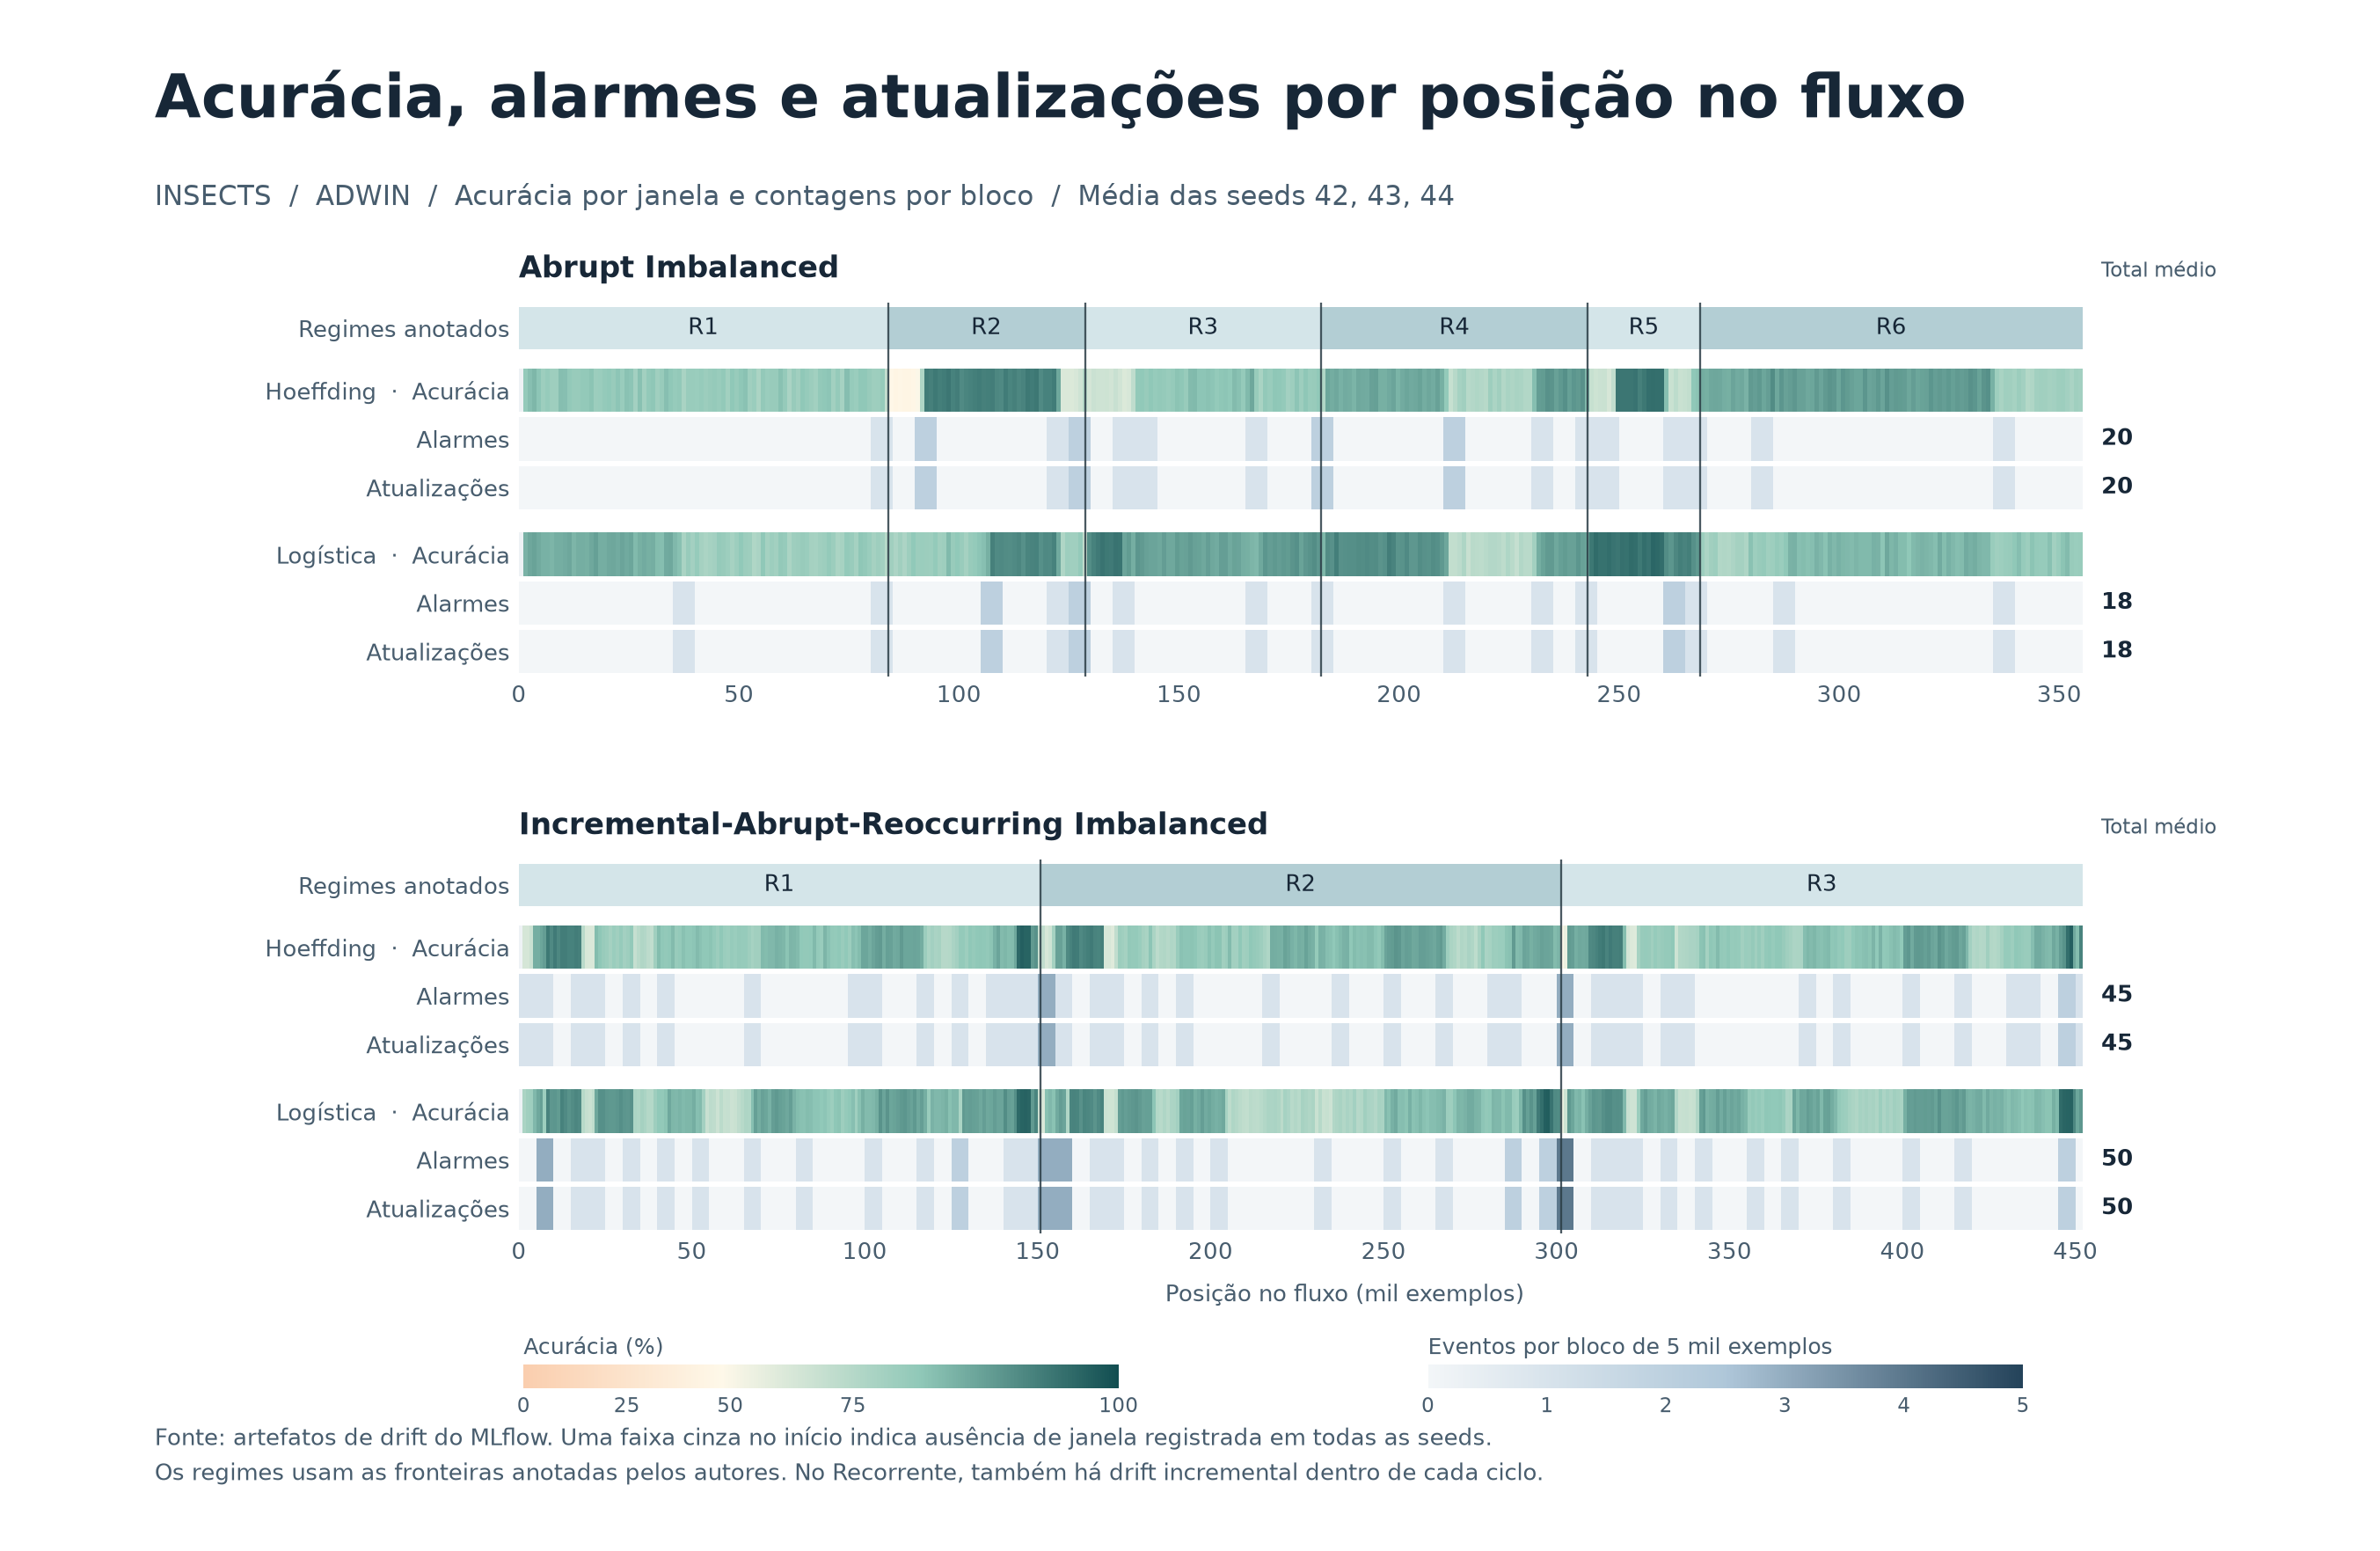

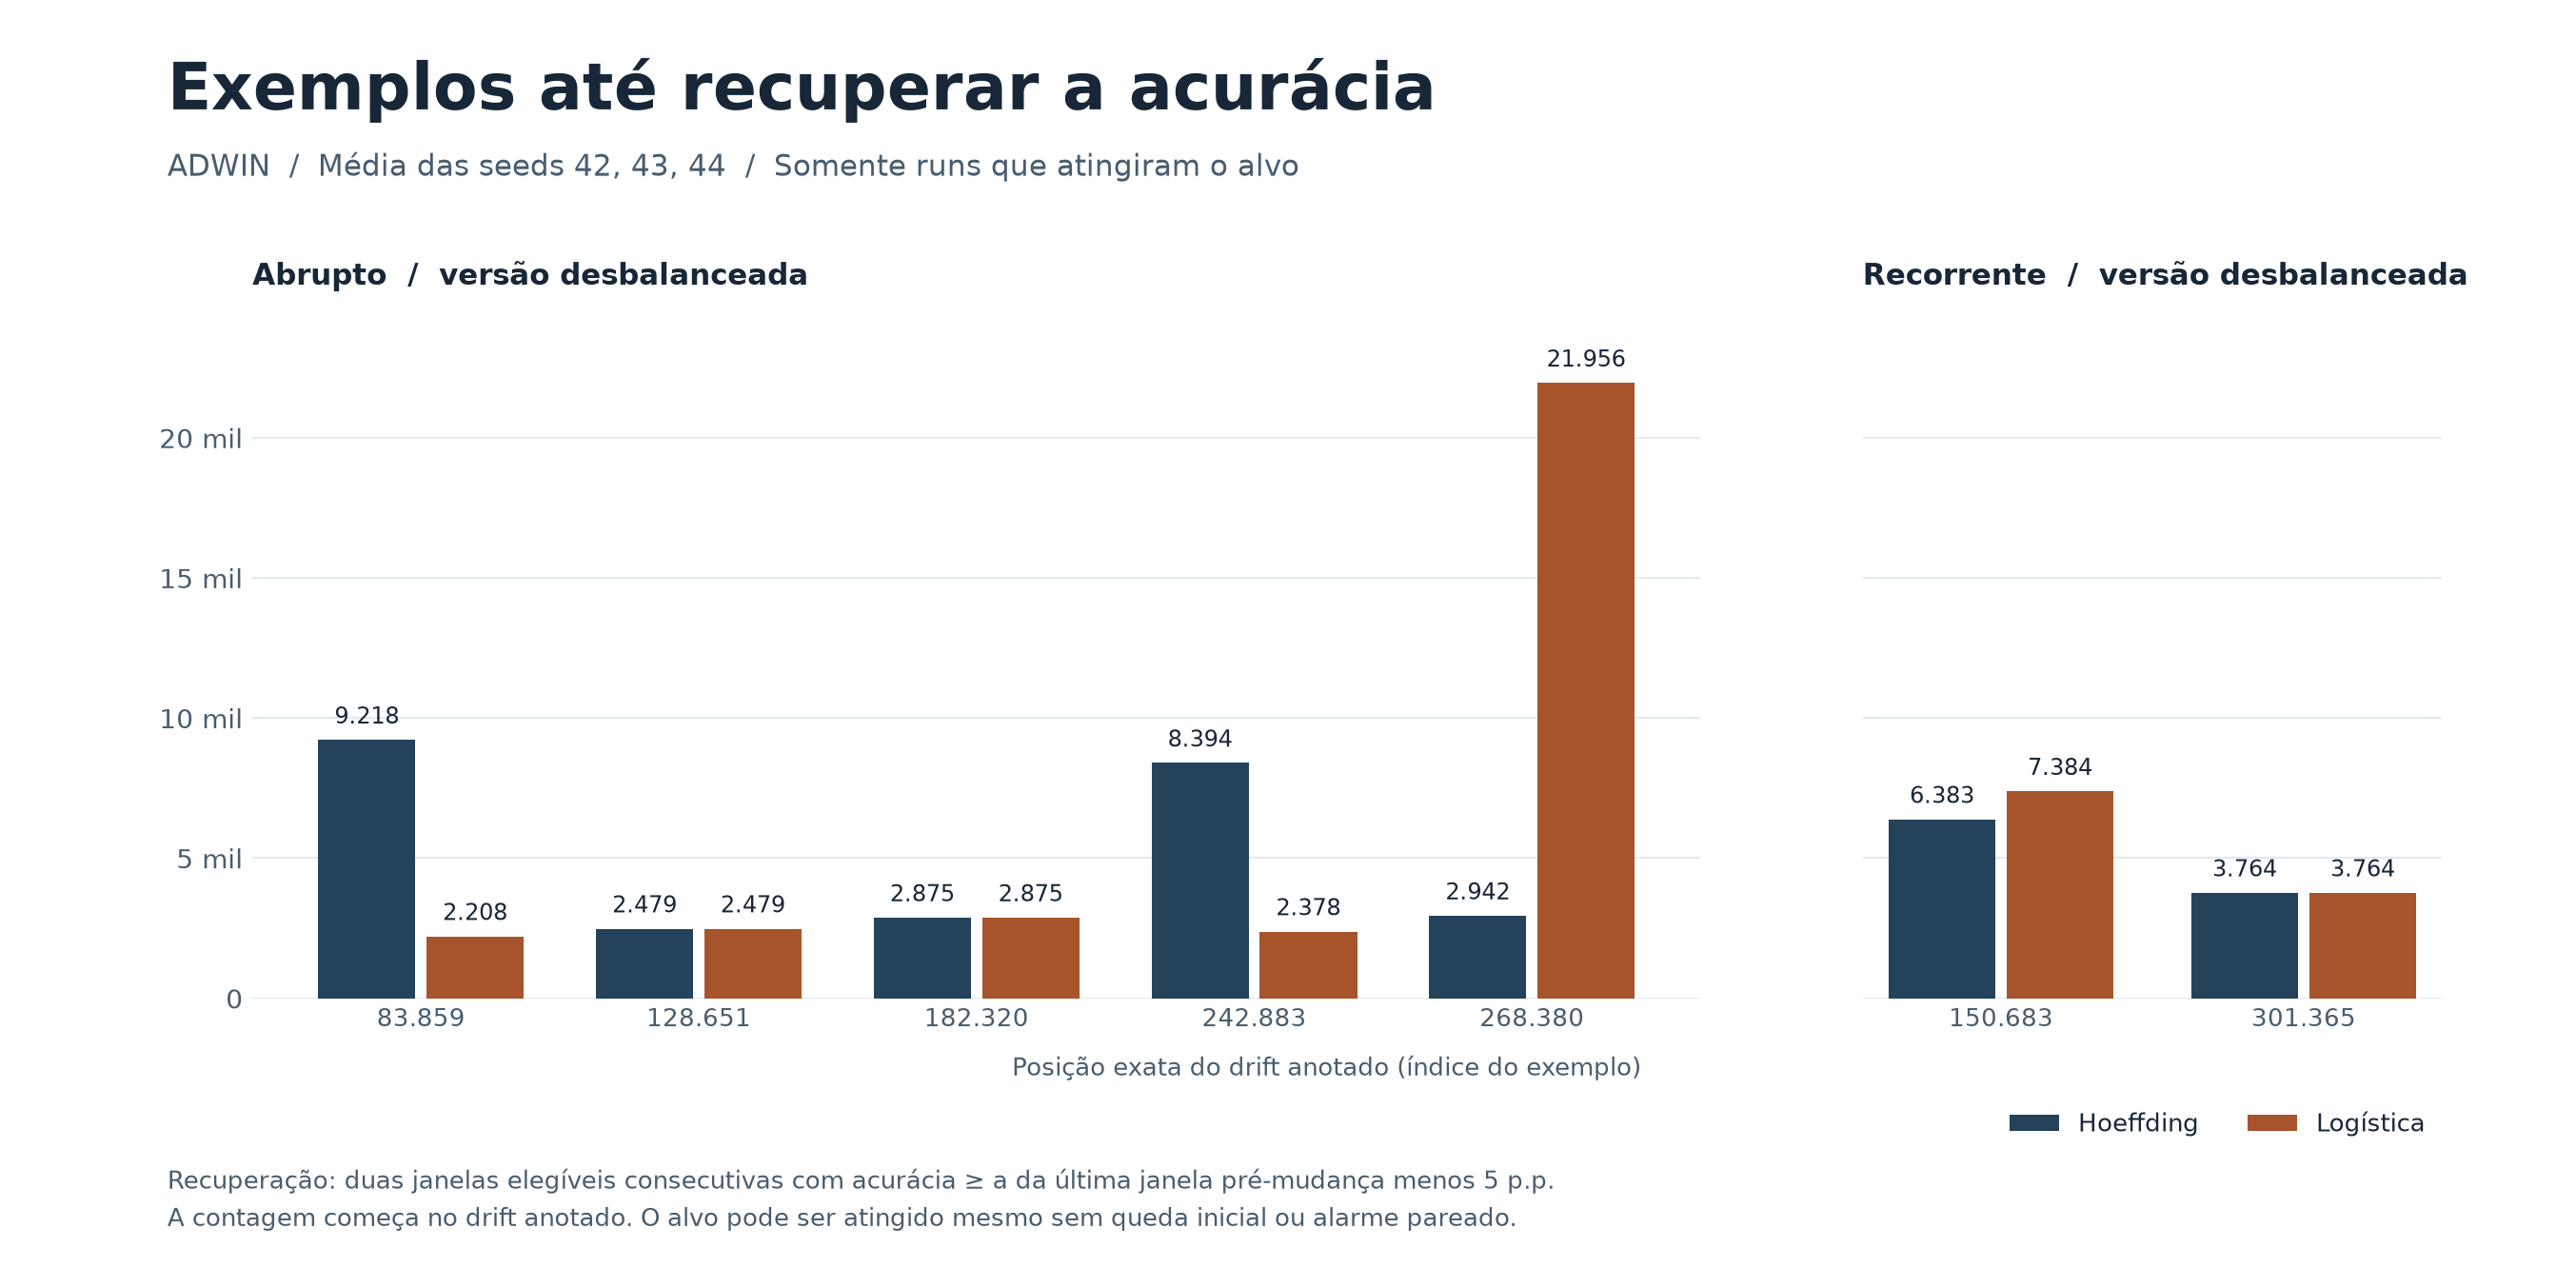

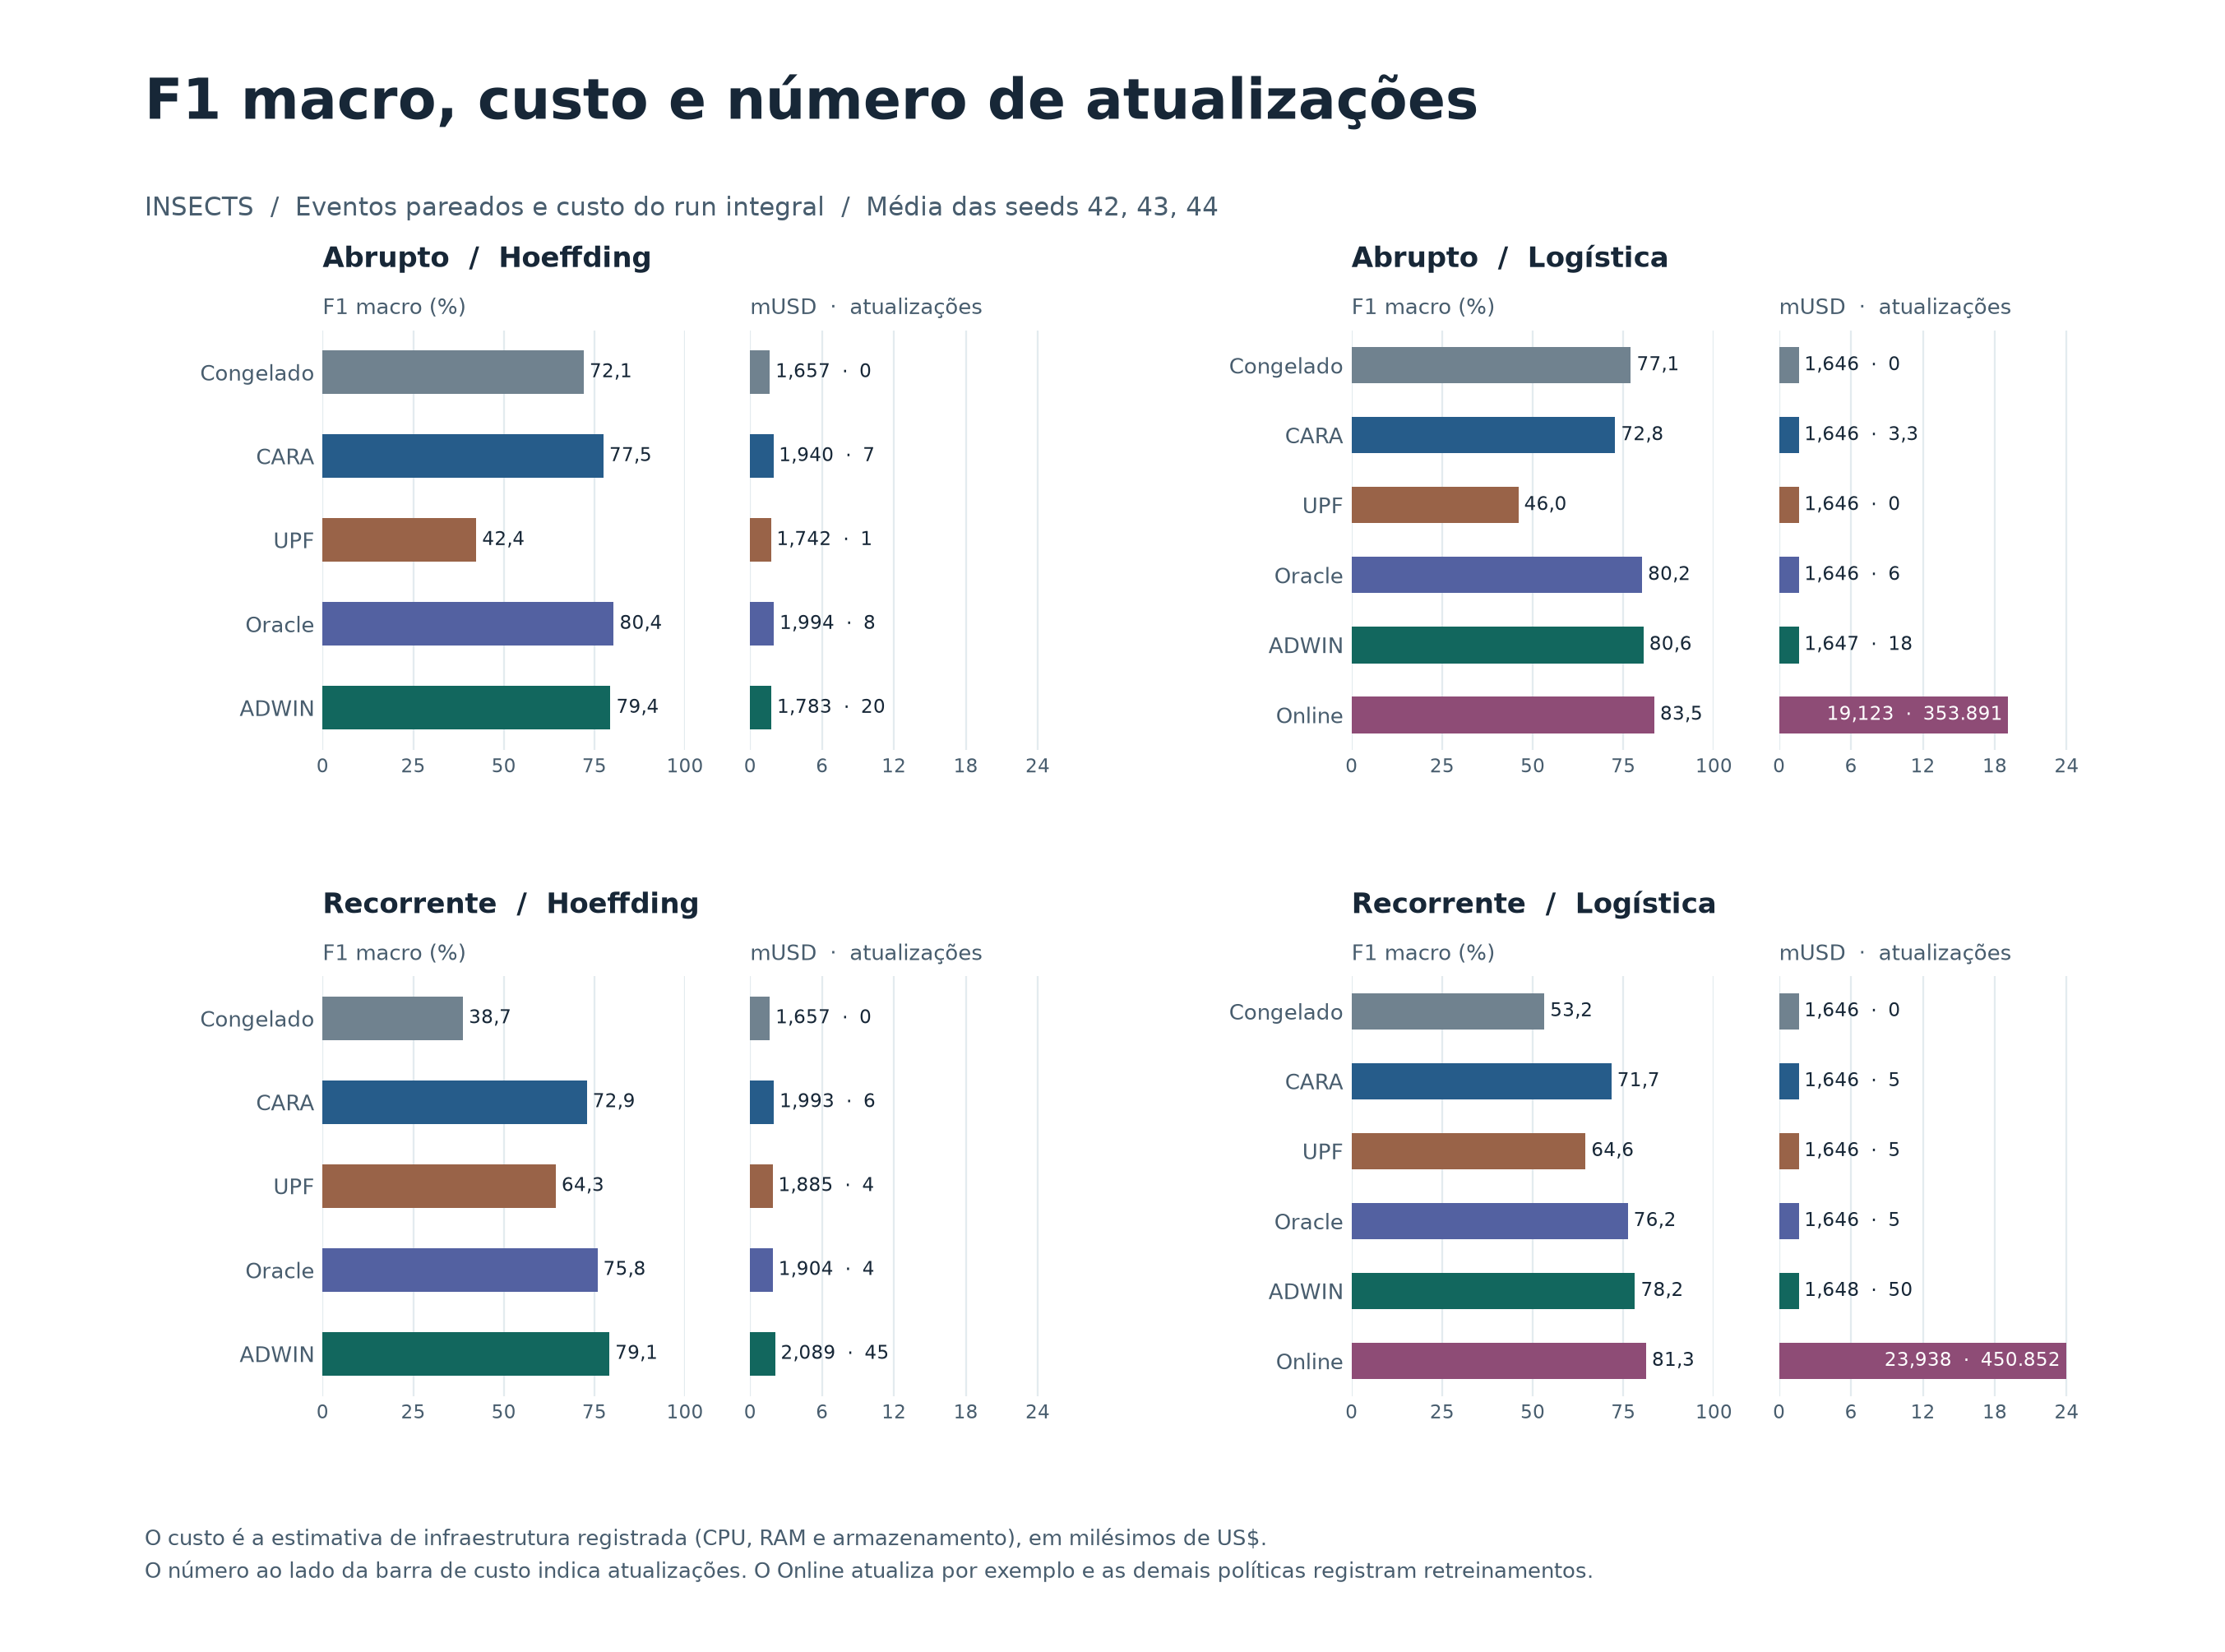

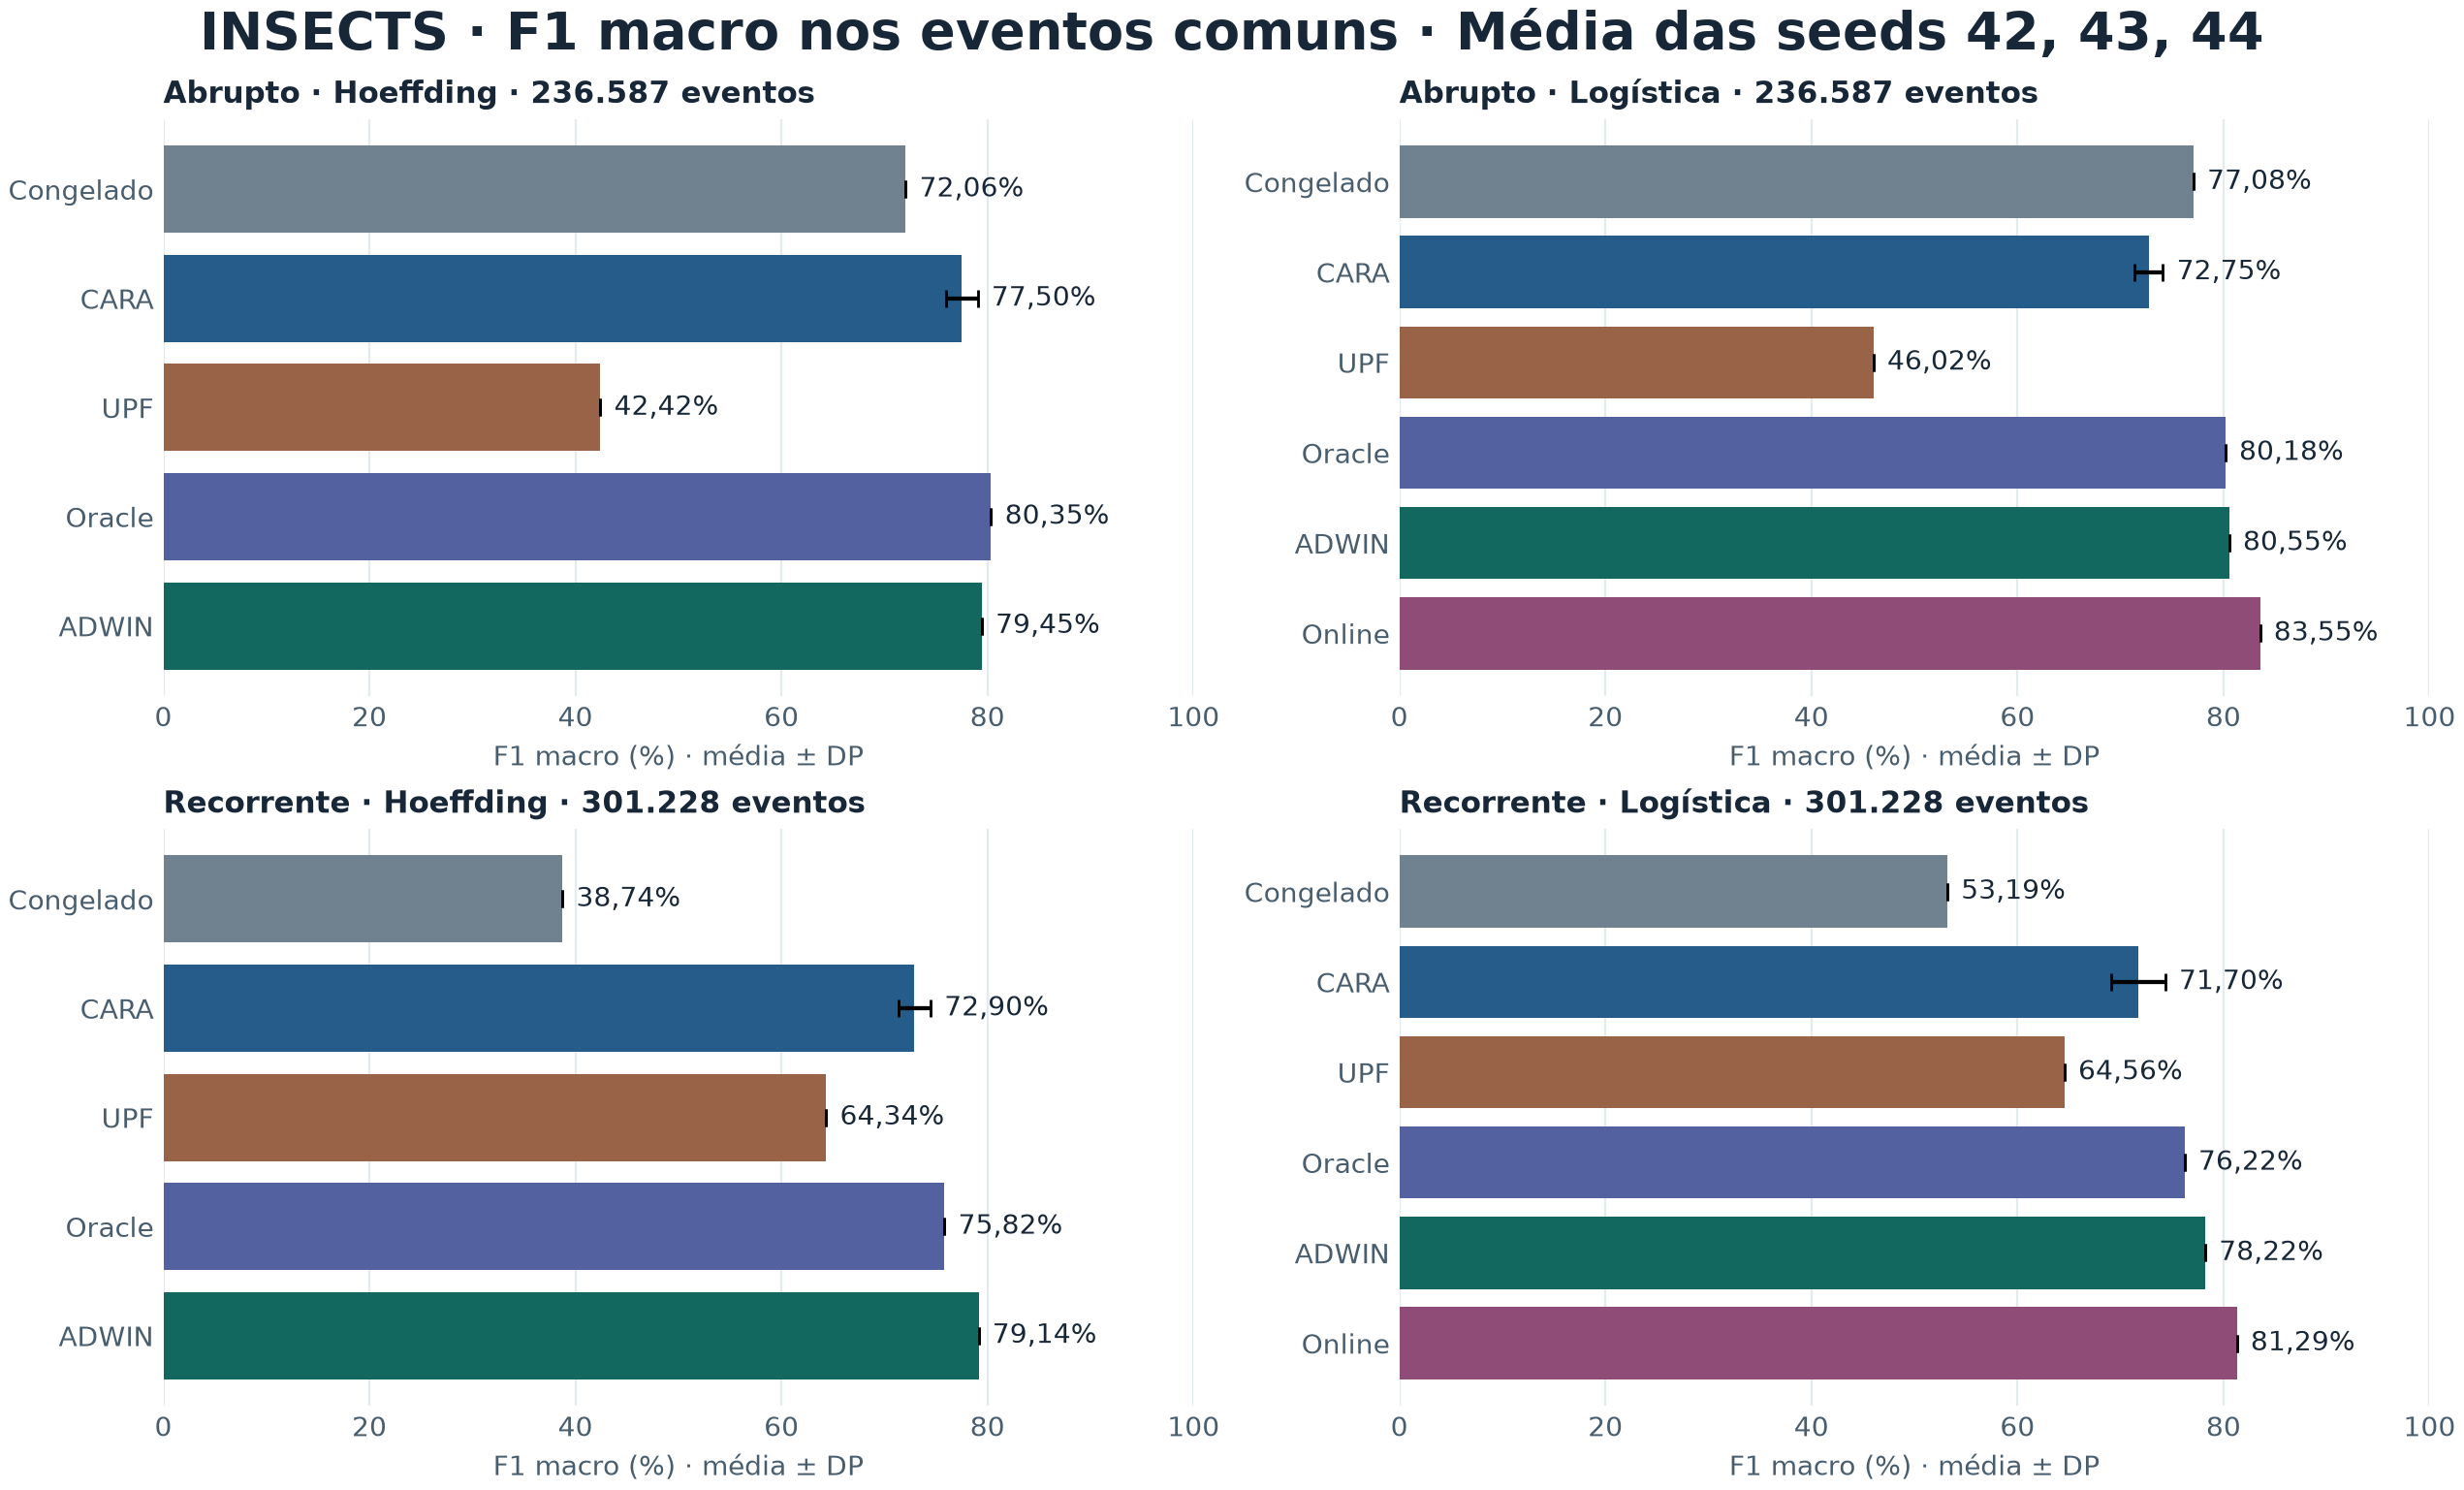

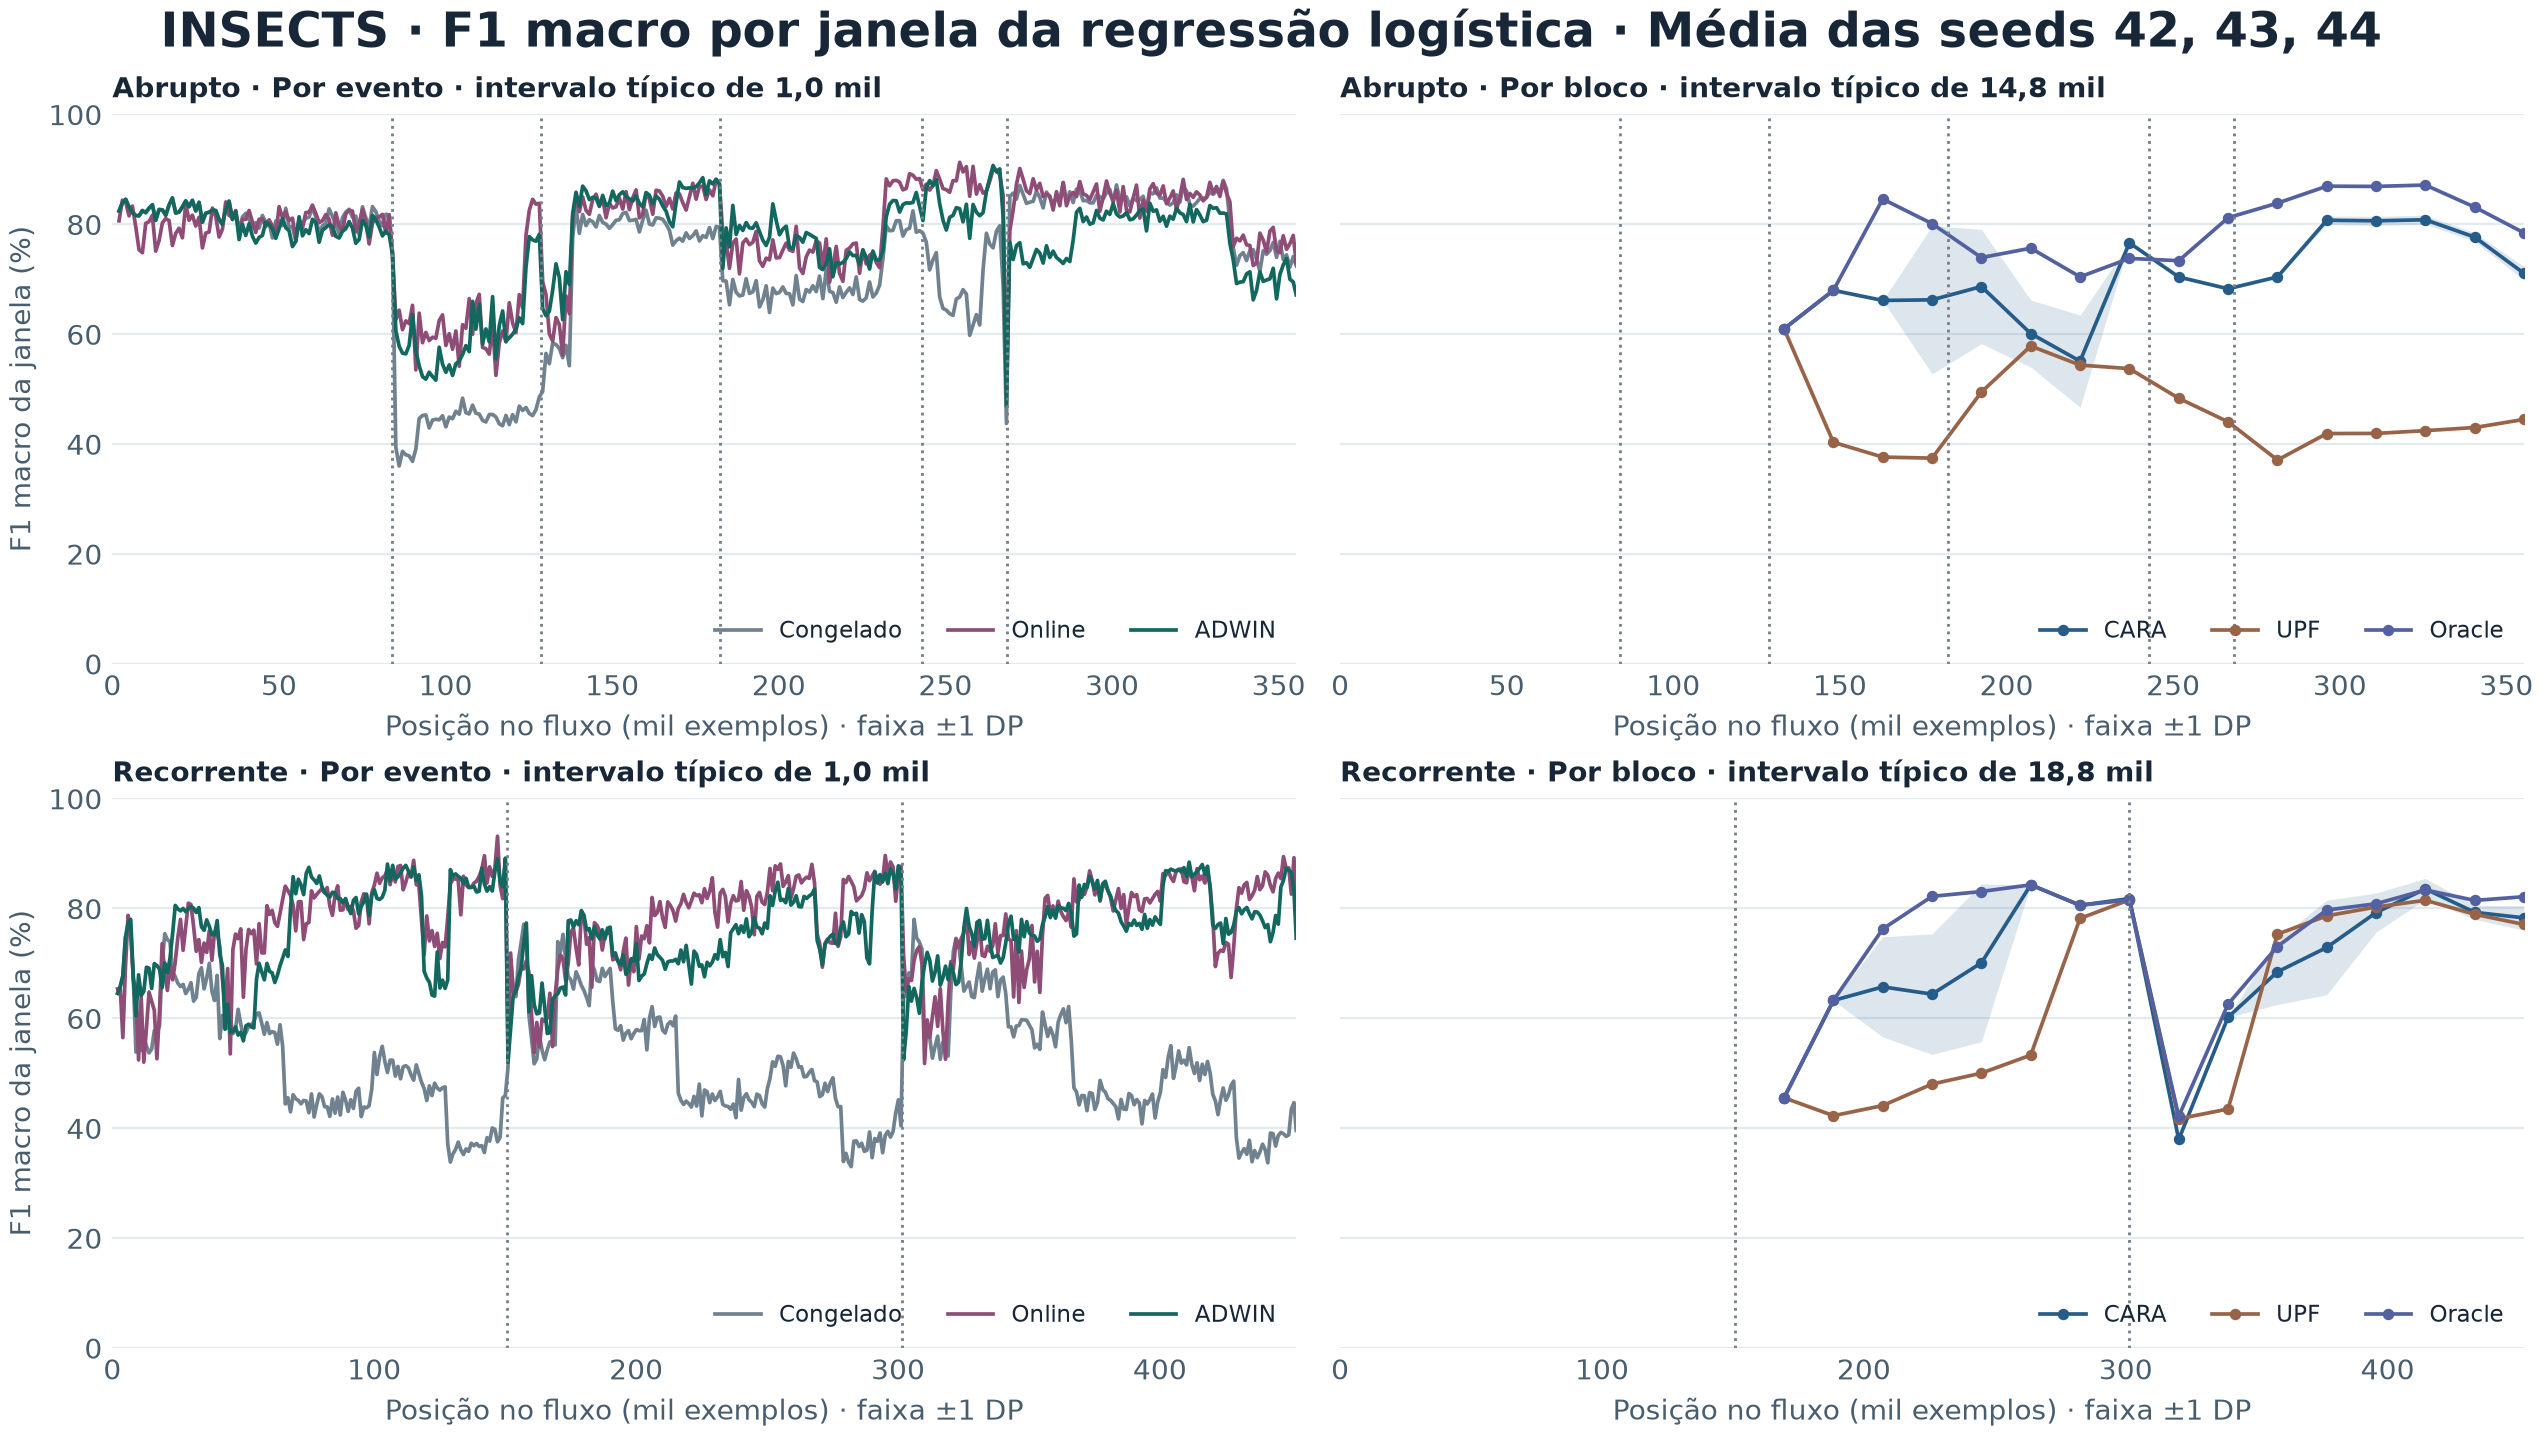

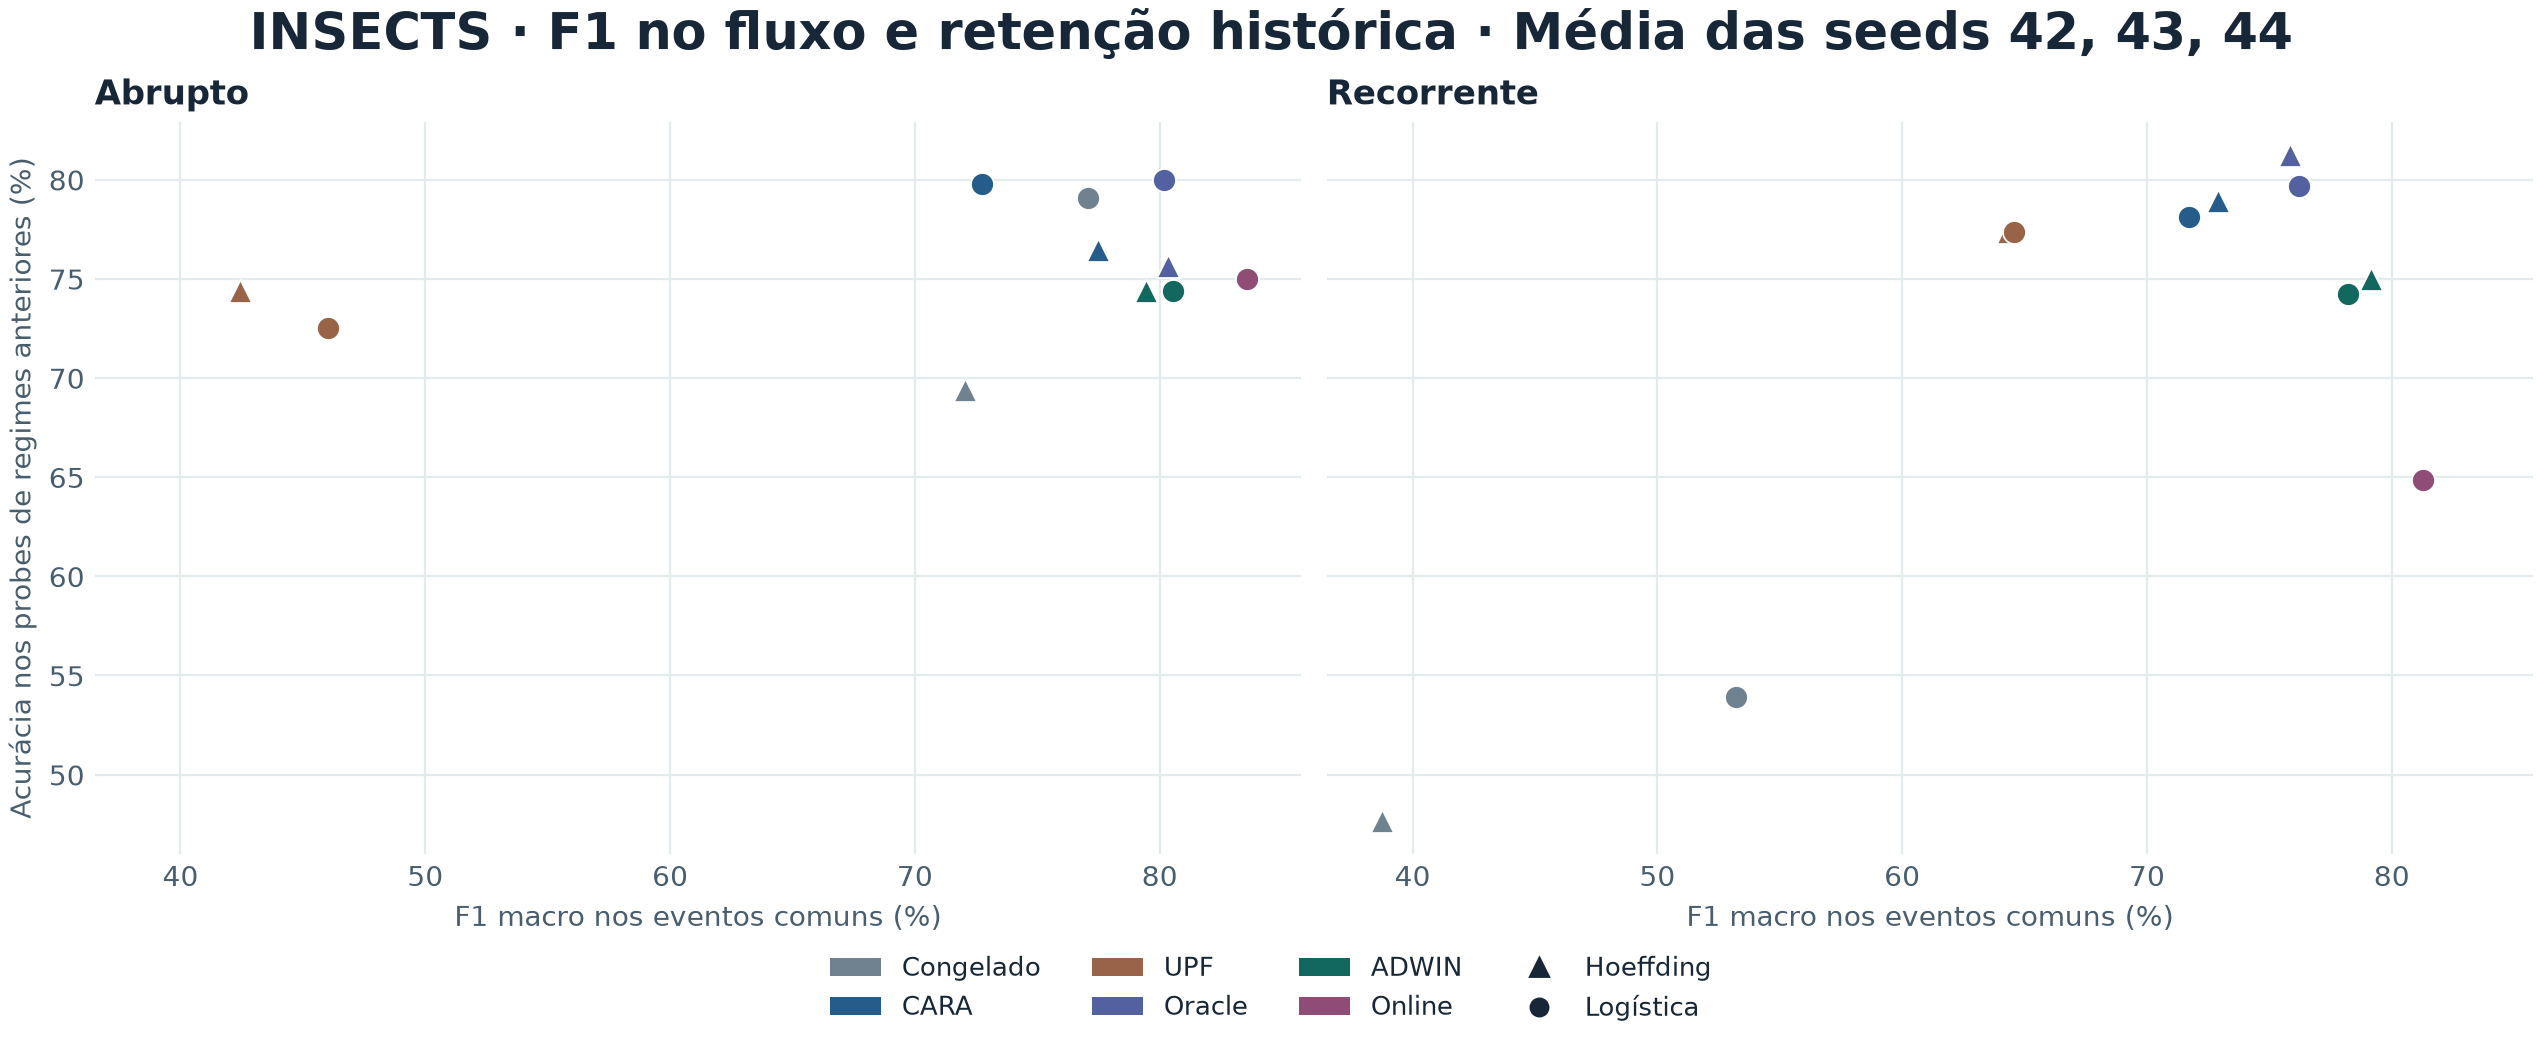

In [5]:
pdf = export_figures(figures, SAIDA)
print(f"{len(figures)} figuras exportadas para {SAIDA}")
print(f"PDF: {pdf.name}")
for name, fig in figures.items():
    display(Image(filename=str(SAIDA / "figuras" / f"{name}.png"), width=1100))
    plt.close(fig)